# Making a Lodos surface from a mesh

A Lodos surface is what Lodos's collision needs of a body: its vertices, which are tested
against the other body's signed distance field, and its own signed distance field (SDF), against
which the other body's vertices are tested. Notebook 02 loaded pre-built surfaces; this notebook
makes one from a triangle mesh `data/armadillo.obj` --
and then simulates it:

1. the mesh, which must be closed and outward-facing;
2. its vertices in the order of a space-filling curve;
3. the voxel grid the field is sampled on;
4. the bake: the signed distance on the grid, fitted with a tricubic B-spline;
5. checks of the field against the mesh;
6. the file, `surface_data.npz`, and loading it back;
7. the surface in a scene, at five sizes.

Making surfaces needs the `mesh` extra (`torch`, `trimesh`, `tqdm`, `pyvista`):
`pip install ".[mesh]"`, or `uv sync`, whose default groups include it.

In [1]:
import os
os.environ.setdefault("MUJOCO_GL", "egl")  # headless rendering; use "glfw" on a desktop

import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import trimesh
import warp as wp

wp.config.log_level = wp.LOG_WARNING  # no init banner
wp.init()
print("device:", wp.get_device())

device: cuda:0


In [2]:
class Camera:
    """Draws an MJCF model the way MuJoCo would, at a `qpos` -- one world of a Lodos `Sim` with `sim.mjm`."""

    def __init__(self, model, height=360, width=480, distance=8.0, azimuth=135.0, elevation=-20.0, lookat=(0, 0, 1)):
        self.model = model
        self.model.vis.headlight.ambient[:] = 0.35
        self.model.vis.headlight.diffuse[:] = 0.6
        self.data = mujoco.MjData(self.model)
        self.renderer = mujoco.Renderer(self.model, height, width)
        self.cam = mujoco.MjvCamera()
        self.cam.distance, self.cam.azimuth, self.cam.elevation = distance, azimuth, elevation
        self.cam.lookat[:] = lookat

    def __call__(self, qpos=None):
        if qpos is not None:
            self.data.qpos[:] = qpos
        mujoco.mj_kinematics(self.model, self.data)
        self.renderer.update_scene(self.data, camera=self.cam)
        return self.renderer.render()

## 1. The mesh

The bake signs its field by asking `wp.mesh_query_point` whether a point lies inside the mesh,
which only a closed mesh, wound consistently with its normals pointing out, can answer. `data/armadillo.obj` was preprocessed using the tools in `tools/mesh_processing/` to have these properties.

In [3]:
from lodos.col.sdf import io as sdf_io

MESH = Path("data/armadillo.obj")
mesh = trimesh.load_mesh(MESH)
length = mesh.edges_unique_length
print(f"{len(mesh.vertices)} vertices, {len(mesh.edges_unique)} edges, {len(mesh.faces)} faces; watertight: "
      f"{mesh.is_watertight}, consistently wound: {mesh.is_winding_consistent}, volume {mesh.volume:.3f} m^3")
print(f"extent {mesh.extents.round(3)} m; edges {length.min() * 1e3:.0f}-{length.max() * 1e3:.0f} mm long, "
      f"{np.median(length) * 1e3:.0f} mm (median)")
v, e, f = sdf_io.load_mesh(MESH)  # the vertices (V, 3), the unique edges (E, 2), the faces (F, 3)

451 vertices, 1347 edges, 898 faces; watertight: True, consistently wound: True, volume 0.354 m^3
extent [1.377 1.23  1.639] m; edges 43-168 mm long, 110 mm (median)


## 2. Curve order

Lodos's broadphase cuts a surface's vertices into tiles of consecutive indices, 8 by default
(`make_collision_context`'s `tile_size`), and tests each tile's bounding sphere against the other
body's field before any of its vertices: rejecting a tile rejects its eight vertices at once, and
a tile's sphere is only as small as its vertices are close together. Therefore, `lodos.col.sdf.io.process_mesh` replaces a mesh's default (most often random) vertex order is by the order of a Hilbert
curve through the vertices (or a Morton curve, `encoding="morton"`) and renumbers the edges and
faces to match. The curve runs through the vertices
quantized on a grid of spacing `eps / eps_divisor`, `eps` the distance between the two closest,
with `depth` bits per axis.

In [4]:
v_c, e_c, f_c, e_l = sdf_io.process_mesh(v, e, f, eps_divisor=50, depth=16, encoding="hilbert")  # e_l: edge lengths

def tile_radii(v, k=8):
    # The radius of each run of k consecutive vertices' bounding sphere, centred on the run's box,
    # as make_collision_context bounds a tile.
    runs = [v[i:i + k] for i in range(0, len(v), k)]
    return np.array([np.linalg.norm(q - (q.min(axis=0) + q.max(axis=0)) / 2, axis=1).max() for q in runs])

for name, order in (("in the file's order", v), ("in Hilbert order", v_c)):
    gap = np.linalg.norm(np.diff(order, axis=0), axis=1)
    print(f"{name:19s}: consecutive vertices {np.median(gap) * 1e3:3.0f} mm apart (median), {gap.max() * 1e3:4.0f} mm "
          f"at most; a tile of 8 within {np.median(tile_radii(order)) * 1e3:3.0f} mm of its centre (median)")
print("the same vertices:", np.array_equal(np.unique(v, axis=0), np.unique(v_c, axis=0)),
      f"| the same solid: volume {trimesh.Trimesh(v_c, f_c, process=False).volume:.3f} m^3")

Quantization eps is: 0.0008626383948816557
Recommended minimum encoding depth is: 11
in the file's order: consecutive vertices 222 mm apart (median), 1540 mm at most; a tile of 8 within 442 mm of its centre (median)
in Hilbert order   : consecutive vertices 114 mm apart (median),  765 mm at most; a tile of 8 within 201 mm of its centre (median)
the same vertices: True | the same solid: volume 0.354 m^3


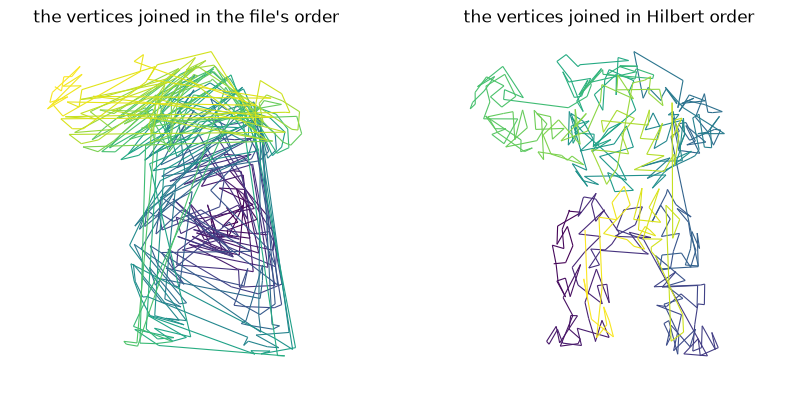

In [5]:
from mpl_toolkits.mplot3d.art3d import Line3DCollection

lo, hi = v.min(axis=0), v.max(axis=0)
fig = plt.figure(figsize=(10, 5.5))
for k, (name, order) in enumerate((("the file's order", v), ("Hilbert order", v_c))):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.add_collection(Line3DCollection(np.stack([order[:-1], order[1:]], axis=1), cmap="viridis",
                                       array=np.arange(len(order) - 1), linewidth=0.8))
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), zlim=(lo[2], hi[2]))
    ax.set_box_aspect(hi - lo, zoom=1.25)
    ax.view_init(elev=5, azim=-70)
    ax.set_axis_off()
    ax.set_title(f"the vertices joined in {name}")
plt.show()

In [6]:
from lodos.col.sdf import implicit

VOXELS, DILATION = 100, 2.0               # voxels along the box's longest edge; the box's size over the mesh's
lo, hi = v_c.min(axis=0), v_c.max(axis=0)
size = (hi - lo) * DILATION
h = size.max() / VOXELS                   # the voxels' edge (m)
N = np.ceil(size / h - 1e-9).astype(int)  # voxels per axis; the tolerance keeps the longest axis at VOXELS
box = np.stack([(lo + hi) / 2 - N * h / 2, (lo + hi) / 2 + N * h / 2])
grid, knots, centres, _ = implicit.create_voxel_grid_from_verts(v_c, N=N, grid_aabb=box, verbose=False)
print(f"N = {N}: voxels of {h * 1e3:.1f} mm in a box of {np.round(box[1] - box[0], 3)} m")
print(f"{np.prod(N + 1):,} knots, {np.prod(N + 3):,} spline coefficients and {np.prod(N):,} voxel centres: "
      f"{4 * (np.prod(N + 3) + np.prod(N)) / 1e6:.1f} MB in float32")

N = [ 85  76 100]: voxels of 32.8 mm in a box of [2.787 2.492 3.279] m
668,822 knots, 716,056 spline coefficients and 646,000 voxel centres: 5.4 MB in float32


## 4. The bake

`create_implicit_surface_from_mesh` samples the signed distance at every knot of a voxel grid
(`wp.mesh_query_point`, over a `wp.Mesh` and its BVH) and fits a tricubic B-spline to the
samples, with `N + 3` coefficients along each axis. The narrowphase evaluates that spline at a vertex
for its distance, and the spline's gradient for the contact normal. It also samples the distance
at every voxel's centre, for the broadphase's prefilter. A vertex goes on to the narrowphase only
where the distance at its voxel's centre is less than the voxel's circumradius `r`.

In [7]:
t0 = time.perf_counter()
imps = implicit.create_implicit_surface_from_mesh(v_c, f_c, grid, knots, centres)
coeffs, vsdf = imps.sdf_coeffs.numpy(), imps.vsdf_values.numpy()
print(f"baked in {time.perf_counter() - t0:.1f} s: spline coefficients {coeffs.shape}, voxel-centre distances {vsdf.shape}")

baked in 0.3 s: spline coefficients (88, 79, 103), voxel-centre distances (85, 76, 100)


The field on a vertical plane through the middle of the box: negative inside the armadillo,
positive outside, its zero contour (black) on the mesh's own section (gold, dashed).

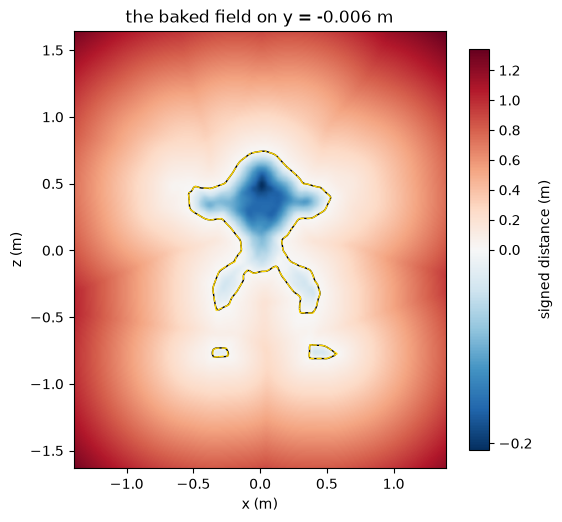

In [8]:
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm

y0 = (lo[1] + hi[1]) / 2
x = np.linspace(box[0, 0], box[1, 0], 300)
z = np.linspace(box[0, 2], box[1, 2], 350)
X, Z = np.meshgrid(x, z)
d = implicit.compute_sdf_batch(np.stack([X.ravel(), np.full(X.size, y0), Z.ravel()], axis=1), imps).reshape(X.shape)
cut = trimesh.intersections.mesh_plane(mesh, plane_normal=(0, 1, 0), plane_origin=(0, y0, 0))  # (n, 2, 3) segments

fig, ax = plt.subplots(figsize=(6, 6.5))
im = ax.imshow(d, origin="lower", extent=(x[0], x[-1], z[0], z[-1]), cmap="RdBu_r",
               norm=TwoSlopeNorm(vmin=d.min(), vcenter=0.0, vmax=d.max()))
ax.contour(x, z, d, levels=[0], colors="k", linewidths=1)
ax.add_collection(LineCollection(cut[:, :, [0, 2]], colors="gold", linestyles="--", linewidths=1))
ax.set(xlabel="x (m)", ylabel="z (m)", title=f"the baked field on y = {y0:.3f} m")
fig.colorbar(im, ax=ax, label="signed distance (m)", shrink=0.8)
plt.show()

## 5. Checks

The field should read zero on the mesh, and its gradient should point along the mesh's normals.
Both are checked at 20,000 points spread over the mesh's faces (`trimesh.sample.sample_surface`). The field's zero level set, obtained by running marching cubes at twice the grid's
resolution (`create_pv_grid`), is drawn on the right:

on the mesh: |sdf| 0.80 mm (mean), 10.0 mm at most -- 0.024 and 0.31 of a voxel
the gradient against the face's normal: 4.6 degrees (median), 42 (99th percentile), 79 at most


the zero level set: 24,764 vertices, volume 0.353 m^3 against the mesh's 0.354


""

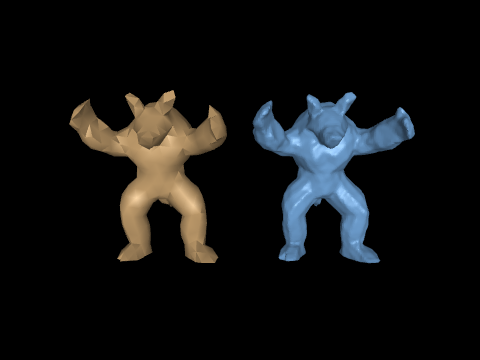

In [9]:
import warnings
from viewer.scenes.assets import CACHE_DIR

warnings.filterwarnings("ignore", message="IProgress not found")  # pyvista loads tqdm's notebook bars; none is drawn
p, face = trimesh.sample.sample_surface(mesh, 20000, seed=0)
d = implicit.compute_sdf_batch(p, imps)
n = implicit.compute_n_batch(p, imps)
angle = np.degrees(np.arccos(np.clip(np.sum(n * mesh.face_normals[face], axis=1), -1, 1)))
print(f"on the mesh: |sdf| {np.abs(d).mean() * 1e3:.2f} mm (mean), {np.abs(d).max() * 1e3:.1f} mm at most -- "
      f"{np.abs(d).mean() / h:.3f} and {np.abs(d).max() / h:.2f} of a voxel")
print(f"the gradient against the face's normal: {np.median(angle):.1f} degrees (median), "
      f"{np.percentile(angle, 99):.0f} (99th percentile), {angle.max():.0f} at most")

image = implicit.create_pv_grid(imps, grid_upsample=2, shrinkage_factor=1.0)
iso = image.contour([0.0], implicit.compute_sdf_batch(np.asarray(image.points), imps), method="marching_cubes")
# VTK winds a contour's faces along the decreasing field, so they are reversed to face out.
iso = trimesh.Trimesh(np.asarray(iso.points), np.asarray(iso.faces).reshape(-1, 4)[:, 1:][:, ::-1], process=False)
print(f"the zero level set: {len(iso.vertices):,} vertices, volume {iso.volume:.3f} m^3 against the mesh's {mesh.volume:.3f}")

OUT = CACHE_DIR / "notebooks" / "armadillo"  # the directory for derived files: .scratch/ in a clone
OUT.mkdir(parents=True, exist_ok=True)
iso.export(OUT / "level_set.obj")
pair = mujoco.MjModel.from_xml_string(f"""<mujoco>
  <asset><mesh name="mesh" file="{MESH.resolve()}"/><mesh name="level_set" file="{OUT / 'level_set.obj'}"/></asset>
  <worldbody>
    <geom type="mesh" mesh="mesh" pos="-0.8 0 0" rgba="0.8 0.65 0.45 1"/>
    <geom type="mesh" mesh="level_set" pos="0.8 0 0" rgba="0.45 0.65 0.85 1"/>
  </worldbody>
</mujoco>""")
media.show_image(Camera(pair, distance=4.2, azimuth=90, elevation=-5, lookat=(0, 0, 0))())

## 6. The file

`surface_data.npz` holds the arrays above under the names `lodos.col.sdf.load_surface_data`
reads: the vertices `v`, the edges `e`, the faces `f` and the edge lengths `e_l`; the grid's
corners `p_min` and `p_max`, its voxel counts `N`, edge `h` and circumradius `r`; the spline's
coefficients `sdf_coeffs` and the voxel-centre distances `vsdf_values`.
`lodos.col.sdf.load_surface_file` loads it as the scenes do, adding the vertices' bounding box
(`bbox`) where the file has none.

In [10]:
from lodos.col.sdf import load_surface_file
from viewer.scenes.assets import load_surface

path = OUT / "surface_data.npz"
np.savez(path, v=v_c, e=e_c, f=f_c, e_l=e_l, p_min=np.array(grid.p_min), p_max=np.array(grid.p_max),
         N=np.array(grid.N), h=np.array(grid.h), r=float(grid.r), sdf_coeffs=coeffs, vsdf_values=vsdf)
surf = load_surface_file(path)
print(f"{path.name}: {path.stat().st_size / 1e6:.1f} MB, loaded with {len(surf.v)} vertices and the {surf.spline_type} spline")

shipped = load_surface("armadillo")
print("against the shipped armadillo: the same vertices and faces in the same order:",
      np.array_equal(surf.v, shipped.v) and np.array_equal(surf.f, shipped.f),
      "| the same grid:", all(np.allclose(getattr(surf, k), getattr(shipped, k)) for k in ("p_min", "p_max", "N", "h", "r")),
      f"| coefficients within {np.abs(surf.sdf_coeffs - shipped.sdf_coeffs).max() * 1e6:.2f} um of these")

surface_data.npz: 5.5 MB, loaded with 451 vertices and the cubic spline
against the shipped armadillo: the same vertices and faces in the same order: True | the same grid: True | coefficients within 0.02 um of these


## 7. The surface in a scene

Let us create a scene using the armadillo surface created in the steps above.

In [11]:
from lodos import sim as lsim, step
from lodos.col.sdf import PlaneSurface, scale_surface, write_surface_obj

SIZES = (1.0, 0.85, 0.7, 0.55, 0.4)
obj = write_surface_obj(surf, OUT / "armadillo.obj")
meshes = "".join(f'<mesh name="arm{i}" file="{obj}" scale="{s} {s} {s}" inertia="exact"/>' for i, s in enumerate(SIZES))
bodies = "".join(f'<body name="b{i}" pos="0 0 {1 + 2 * i}"><freejoint/><geom name="g{i}" type="mesh" mesh="arm{i}" '
                 f'density="100" rgba="{0.35 + 0.12 * i} 0.55 {0.85 - 0.12 * i} 1"/></body>' for i in range(len(SIZES)))
mjm = mujoco.MjModel.from_xml_string(f"""<mujoco>
  <option timestep="0.002" cone="elliptic"/>
  <asset>{meshes}</asset>
  <worldbody>
    <geom name="floor" type="plane" size="12 12 0.1" rgba="0.8 0.8 0.8 1"/>
    {bodies}
  </worldbody>
</mujoco>""")
print("masses:", ", ".join(f"{mjm.body(f'b{i}').mass[0]:.1f}" for i in range(len(SIZES))), "kg; the full size's volume "
      f"at density 100: {100 * mesh.volume:.1f} kg")

nb = len(SIZES)
geom = lambda name: mujoco.mj_name2id(mjm, mujoco.mjtObj.mjOBJ_GEOM, name)
pairs = [[a, b] for a in range(nb) for b in range(nb) if a != b] + [[a, nb] for a in range(nb)]
params = lsim.default_pair_params(0.8, len(pairs))
params[:, 1] = 5.0e3    # spring stiffness, as viewer.scenes.armadillo sets it
params[:, 3] = 0.15     # dissipation
surfaces = lsim.Surfaces(surfaces=[scale_surface(load_surface_file(path), s) for s in SIZES] + [PlaneSurface()],
                         geoms=[geom(f"g{i}") for i in range(nb)] + [geom("floor")], pairs=pairs, params=params, mu=0.8)

def stacks(B, seed=0, gap=0.15):
    # Each world's bodies one above another, each turned at random, `gap` between one's lowest vertex and the next's.
    rng = np.random.default_rng(seed)
    q0 = np.zeros((B, mjm.nq))
    for w in range(B):
        top = 0.0
        for i, s in enumerate(surfaces.surfaces[:nb]):
            q = rng.normal(size=4)
            q /= np.linalg.norm(q)
            R = np.zeros(9)
            mujoco.mju_quat2Mat(R, q)
            vz = np.asarray(s.v) @ R.reshape(3, 3)[2]   # the turned vertices' heights
            q0[w, 7 * i:7 * i + 3] = (*rng.uniform(-0.12, 0.12, 2), top + gap - vz.min())
            q0[w, 7 * i + 3:7 * i + 7] = q
            top += gap + vz.max() - vz.min()
    return q0

B = 64
sim = lsim.make_sim(mjm, B, surfaces=surfaces, qpos=stacks(B), nconmax=256, njmax=1024)
replay = step.make_step_graph(sim)
cam = Camera(sim.mjm, distance=7.5, elevation=-15, lookat=(0, 0, 1.2))

frames, peak = [], np.zeros(2, int)
for i in range(2000):  # 4 s
    replay()
    if i % 10 == 0:
        frames.append(cam(sim.drbd.qpos.numpy()[0]))
        peak = np.maximum(peak, (sim.d.nacon.numpy()[0], sim.d.nefc.numpy().max()))
print(f"MJWarp's contacts at most {peak[0]} of {sim.d.naconmax}, rows at most {peak[1]} of {sim.d.njmax} a world; "
      f"Lodos's collision overflowed: {bool(sim.dcol.overflow.numpy().any())}")
media.show_video(frames, fps=50)

masses: 35.4, 21.8, 12.2, 5.9, 2.3 kg; the full size's volume at density 100: 35.4 kg


MJWarp's contacts at most 833 of 16384, rows at most 54 of 1024 a world; Lodos's collision overflowed: False


This browser does not support the video tag.


In [12]:
q = sim.drbd.qpos.numpy().reshape(B, nb, 7)
lowest = np.full((B, nb), np.inf)
for i, s in enumerate(surfaces.surfaces[:nb]):
    for w in range(B):
        R = np.zeros(9)
        mujoco.mju_quat2Mat(R, q[w, i, 3:])
        lowest[w, i] = (np.asarray(s.v) @ R.reshape(3, 3)[2]).min() + q[w, i, 2]
n = int(sim.dcol.ct.numpy()[2])
depth = -sim.dcol.sdf_nCa3.numpy()[:n]
speed = np.linalg.norm(sim.drbd.qvel.numpy().reshape(B, nb, 6)[:, :, :3], axis=2)
print(f"after 4 s: {np.mean(lowest < 1e-3):.0%} of the bodies on the floor, no vertex more than {-lowest.min() * 1e3:.2f} mm "
      f"below it; {n} contacts, {depth.mean() * 1e3:.2f} mm deep (mean), {depth.max() * 1e3:.2f} mm at most; each world's "
      f"fastest body at {np.median(speed.max(axis=1)) * 1e3:.0f} mm/s (median); finite: {np.isfinite(q).all()}")

after 4 s: 93% of the bodies on the floor, no vertex more than 1.30 mm below it; 830 contacts, 0.10 mm deep (mean), 1.42 mm at most; each world's fastest body at 42 mm/s (median); finite: True
